In [1]:
#Importações
%matplotlib ipympl
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans

from Apoio.config import DADOS_SEM_ID, DADOS_SEM_ID_PREPROCESSADOS
from Apoio.auxiliares import graficos_elbow_silhouette, RANDOM_STATE, visualizar_clusters

import warnings
warnings.filterwarnings("ignore") #Warnings tirados para fins de exibição. Remova essa linha de código e sua importação para visualizá-los

In [2]:
df = pd.read_csv(DADOS_SEM_ID)

df.head()

,genero,idade,renda_anual,pontuacao_de_gastos_(1-100)
0,Masculino,19,15,39
1,Masculino,21,15,81
2,Feminino,20,16,6
3,Feminino,23,16,77
4,Feminino,31,17,40


In [3]:
preprocessamento = ColumnTransformer(
    [
        ("standard", StandardScaler(), ["idade", "renda_anual", "pontuacao_de_gastos_(1-100)"]),
        ("onehot", OneHotEncoder(), ["genero"])
    ]
)

In [4]:
preprocessamento.fit_transform(df)

df_preprocessado = pd.DataFrame(preprocessamento.fit_transform(df), columns=preprocessamento.get_feature_names_out())

df_preprocessado.head()

,standard__idade,standard__renda_anual,standard__pontuacao_de_gastos_(1-100),onehot__genero_Feminino,onehot__genero_Masculino
0,-1.424569,-1.738999,-0.434801,0.0,1.0
1,-1.281035,-1.738999,1.195704,0.0,1.0
2,-1.352802,-1.700830,-1.715913,1.0,0.0
3,-1.137502,-1.700830,1.040418,1.0,0.0
4,-0.563369,-1.662660,-0.395980,1.0,0.0


In [5]:
#df_preprocessado.to_csv(DADOS_SEM_ID_PREPROCESSADOS, index=False)

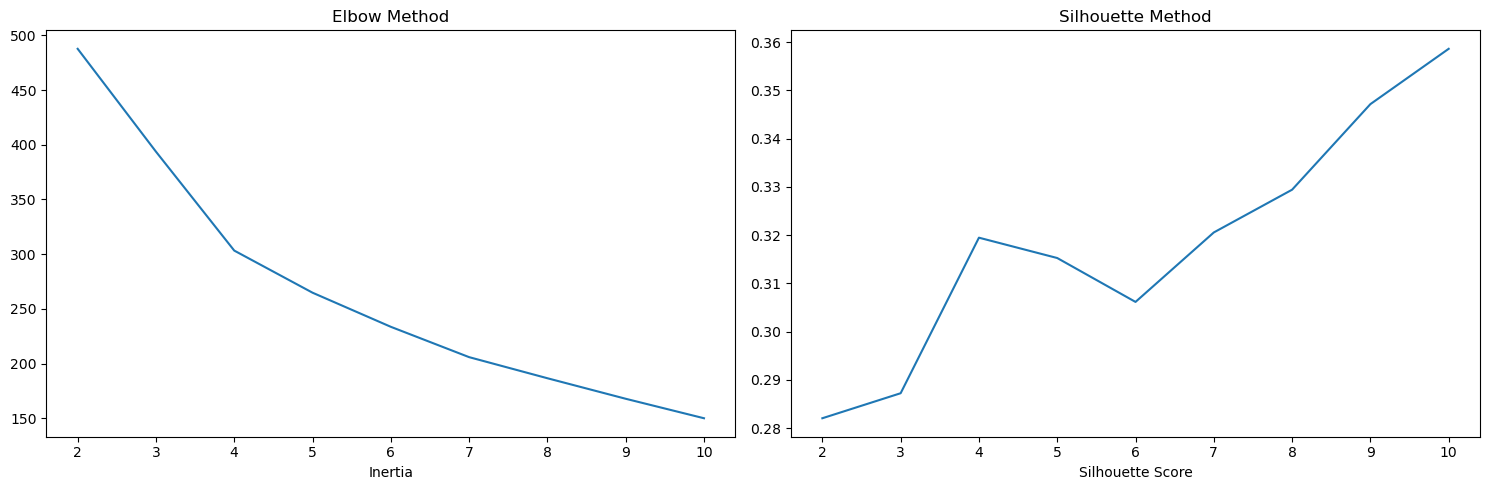

In [6]:
 graficos_elbow_silhouette(df_preprocessado)

In [7]:
pipeline = Pipeline(
    [
        ("preprocessamento", preprocessamento),
        ("clusterizacao", KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE))
    ]
)

pipeline.fit(df)

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('standard', StandardScaler(),
                                                  ['idade', 'renda_anual',
                                                   'pontuacao_de_gastos_(1-100)']),
                                                 ('onehot', OneHotEncoder(),
                                                  ['genero'])])),
                ('clusterizacao',
                 KMeans(n_clusters=5, n_init=10, random_state=42))])

In [8]:
df_clusterizado = df.copy()
df_clusterizado["cluster"] = pipeline["clusterizacao"].labels_

df_clusterizado.head()

,genero,idade,renda_anual,pontuacao_de_gastos_(1-100),cluster
0,Masculino,19,15,39,4
1,Masculino,21,15,81,2
2,Feminino,20,16,6,4
3,Feminino,23,16,77,2
4,Feminino,31,17,40,4


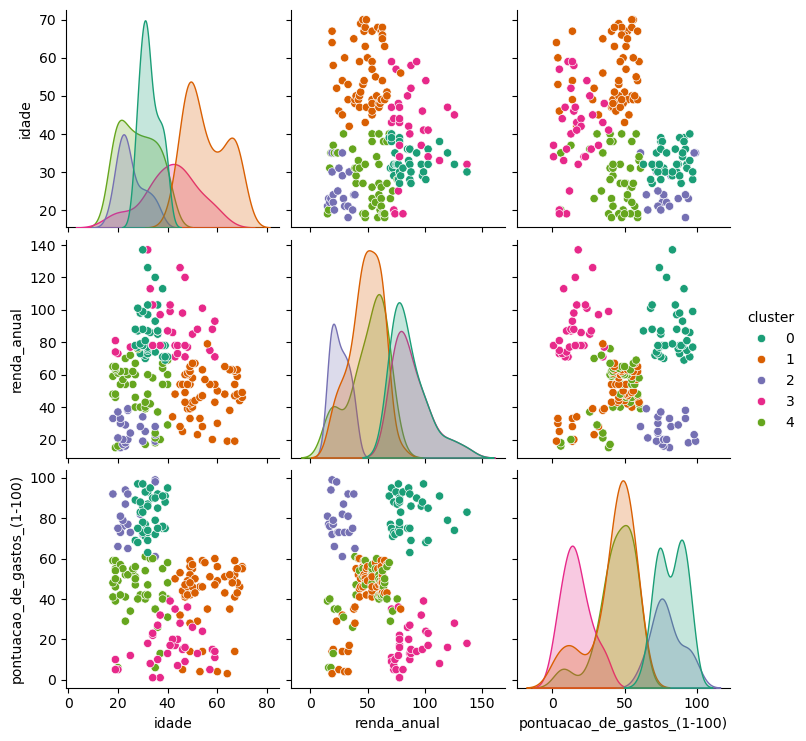

In [9]:
sns.pairplot(df_clusterizado, diag_kind="kde", hue="cluster", palette="Dark2");

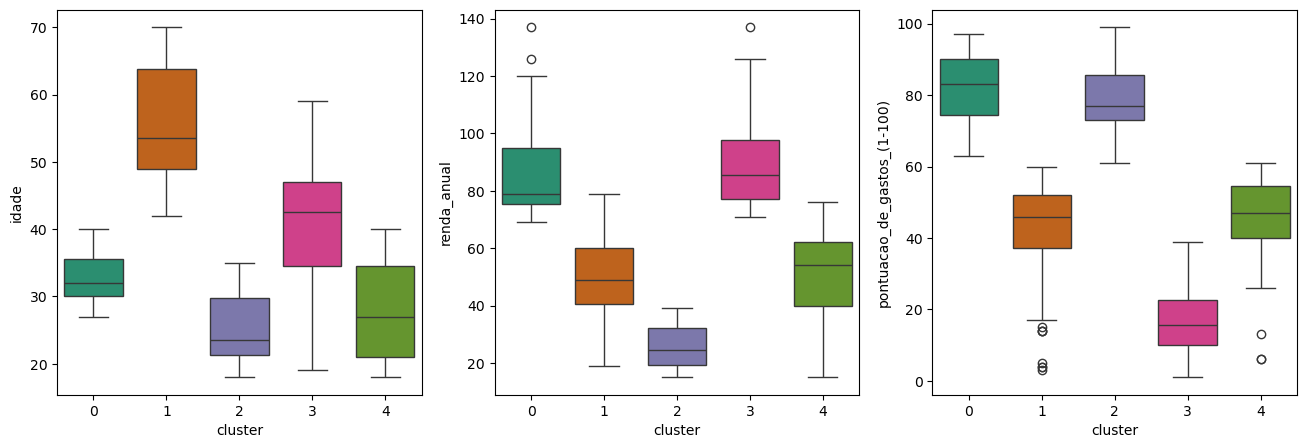

In [10]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))

for ax, col in zip(axs, df_clusterizado.select_dtypes("number")):
    sns.boxplot(data=df_clusterizado, x="cluster", y=col, ax=ax, palette="Dark2")
    
plt.show()

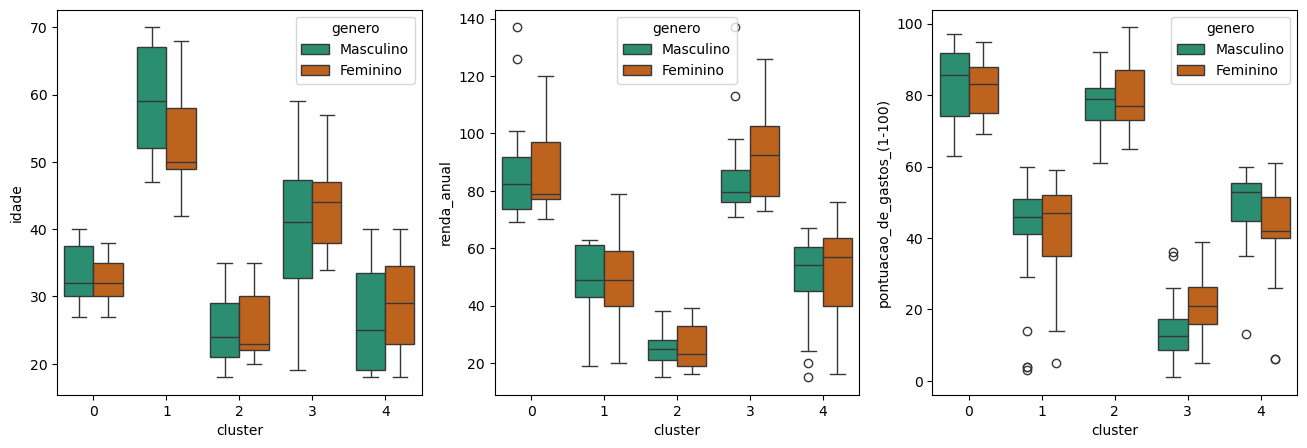

In [11]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 5))

for ax, col in zip(axs, df_clusterizado.select_dtypes("number")):
    sns.boxplot(data=df_clusterizado, x="cluster", y=col, ax=ax, palette="Dark2", hue="genero")
    
plt.show()

In [12]:
centroides = pipeline["clusterizacao"].cluster_centers_[:, :-2]
centroides

array([[-0.44191719,  0.99158305,  1.23950275],
       [ 1.19862745, -0.46098141, -0.32703818],
       [-0.97439592, -1.32954532,  1.13217788],
       [ 0.17329545,  1.06645385, -1.2980103 ],
       [-0.78172248, -0.40306917, -0.21591396]])

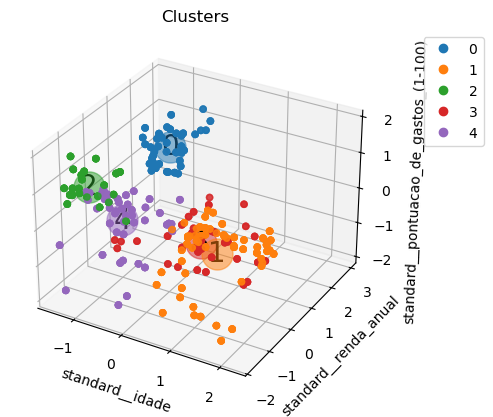

In [13]:
visualizar_clusters(dataframe=df_preprocessado, colunas=["standard__idade", "standard__renda_anual", "standard__pontuacao_de_gastos_(1-100)"],
                   quantidade_cores=5, centroids=centroides, mostrar_pontos=True, coluna_clusters=df_clusterizado["cluster"])